# 16장 Jev 오라클과 사람 오라클 비교

4부를 마무리하는 장이다. 13~15장에서 만든 세 오라클을 같은 틀에 나란히 놓고, 「같은 성능에 이르는 데 무엇이 얼마나 드는가」를 묻는다.

| 오라클 | 내용 |
|---|---|
| 사람 | 시뮬레이션 사람 오라클(정답 라벨). 00_기획안 4.2절의 단가·시간 |
| Jev | 13장 설정(NSMC S1 + 균형 8, YNAT S2 + 균형 7). 사람 검수 없음 |
| 혼합 | 15장 권장 설정. Jev 라벨 중 신뢰도 하위 20%를 사람이 검수. YNAT은 라벨 평활화를 더한다 |

- 16.1 비교 실험 설계
- 16.2 라벨 정확도 비교
- 16.3 학습 곡선 비교
- 16.4 비용 모델 — 사람 라벨 단가와 API 호출 비용
- 16.5 소요 시간 비교
- 16.6 혼합 오라클 구성

질의 전략은 Random과 엔트로피, 시드는 5개다. 엔트로피 칸은 15장 결과 파일을 다시 읽고, Random × Jev·혼합 칸만 새로 돌린다. Jev 호출에 필요한 키·주소·모델 이름은 `jupyter/.env` 에서만 읽는다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


질의 전략으로 쓸 3장의 엔트로피 점수를 다시 싣는다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

Jev 호출 함수, 라벨 체계, 요청 형식, 라벨 판정 함수는 15장과 같다.

In [3]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64, 120, 240, 480, 600):   # 일시 오류·연결 끊김은 쉬었다 다시 보낸다(최대 약 26분)
        try:
            r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                             json=body, timeout=300)
        except requests.ConnectionError:                    # 오래 도는 실험에서 연결이 끊기면 잠시 쉬고 다시 보낸다
            time.sleep(wait)
            continue
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [4]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

In [5]:
# ── 라벨 스키마와 요청 만들기 ────
CHUNK = 50                               # 요청 하나에 넣는 문장 수
TASK_SENT = {"nsmc": "영화 리뷰의 감성을 분류한다.", "ynat": "뉴스 기사 제목의 주제를 분류한다."}
RULES = {"nsmc": ["반어나 비꼼으로 칭찬하는 척하는 리뷰는 부정이다",
                  "칭찬과 불만이 섞이면 글쓴이의 최종 평가를 따른다",
                  "영화 밖의 이야기(배우, 다른 관객)라도 영화에 대한 태도가 드러나면 그 태도를 따른다"],
         "ynat": ["기업·산업·시장·금융·부동산은 경제다. IT 제품·통신·인터넷 서비스·과학 연구는 IT과학이다",
                  "사건·사고·교육·노동·법원·지역 소식은 사회다",
                  "국내 정치·국회·정당·외교·북한은 정치다. 외국 정부와 해외에서 일어난 일은 세계다",
                  "문화·연예·건강·여행·종교·생활 정보는 생활문화다",
                  "경기 결과·선수·구단·대회는 스포츠다"]}

def schema_text(name, level):
    # level 0: 라벨 이름만, 1: 라벨 설명, 2: 설명 + 경계 규칙
    lines = [f"과제: {TASK_SENT[name]}", "라벨:"]
    lines += [f"- {n}: {LABEL_DESC[name][n]}" if level >= 1 else f"- {n}" for n in LABEL_NAMES[name]]
    lines += ["경계 규칙:"] + [f"- {r}" for r in RULES[name]] if level == 2 else []
    return "\n".join(lines)

def build_request(name, texts, schema=1, rich=False, shots=(), near=None):
    # state = 스키마 → 퓨샷 예시 → 분류할 문장. 질문은 문장마다 label_i 하나
    one = lambda t: str(t).replace("\n", " ")
    parts = [] if schema is None else [schema_text(name, schema)]
    parts += ["예시:\n" + "\n".join(f'- "{one(t)}" → {y}' for t, y in shots)] if len(shots) else []
    items = [f"[{i}] {one(t)}" + ("" if near is None else "\n    비슷한 예시: " + "; ".join(f'"{one(a)}" → {b}' for a, b in near[i]))
             for i, t in enumerate(texts)]
    state = "\n\n".join(parts + ["분류할 문장:\n" + "\n".join(items)])
    crit = LABEL_DESC[name] if rich else {n: None for n in LABEL_NAMES[name]}
    ask = f"{TASK[name]}은?" if rich else "라벨"
    qs = {f"label_{i}": {"type": "choice", "instructions": f"[{i}]번 문장의 {ask}", "criteria": crit} for i in range(len(texts))}
    return state, qs

In [6]:
# ── Jev 라벨 판정 ────
def jev_label(name, texts, cfg, near=None):
    # texts를 50개씩 묶어 판정한다. (선택지 확률 행렬, 답의 confidence, 묶음별 사용량)을 돌려준다
    names = LABEL_NAMES[name]
    def one(s):
        state, qs = build_request(name, texts[s:s + CHUNK], near=None if near is None else near[s:s + CHUNK], **cfg)
        t0 = time.perf_counter()
        ans, a, b = jev_ask(state, qs)
        P = [[ans[f"label_{i}"]["probabilities"].get(n, 0.0) for n in names] for i in range(len(qs))]
        c = [ans[f"label_{i}"]["confidence"] for i in range(len(qs))]
        return P, c, dict(n_in=a, n_out=b, t=time.perf_counter() - t0, n=len(qs))
    with ThreadPoolExecutor(MAX_CONC) as ex:
        out = list(ex.map(one, range(0, len(texts), CHUNK)))
    P = np.array([p for o in out for p in o[0]])
    return P / P.sum(1, keepdims=True), np.array([c for o in out for c in o[1]]), pd.DataFrame([o[2] for o in out])

In [7]:
# ── 13~15장에서 넘겨받는 설정과 비용 가정 ────
BEST = {"nsmc": dict(schema=1, n=8), "ynat": dict(schema=2, n=7)}     # 13장: NSMC S1 + 균형 8, YNAT S2 + 균형 7
TAU = {"nsmc": 0.97, "ynat": 0.84}                                    # 14장 τ (16.6절 후보에 쓴다)
MIX = {"nsmc": ("신뢰도", 20, "기본"), "ynat": ("신뢰도", 20, "라벨 평활화")}   # 15장 권장 혼합 오라클
UNIT = {"nsmc": 50, "ynat": 80}                                       # 00_기획안 4.2절 가정: 사람 라벨 단가(원)
SEC = {"nsmc": 8, "ynat": 12}                                         # 00_기획안 4.2절 가정: 사람 라벨 건당 시간(초)
REVIEW = 0.6                                                          # 검수는 단가·시간 모두 60%

def pick_bal(d, idx0, n, rng):
    y0 = d["y_pool"][idx0]
    pick = np.concatenate([rng.choice(idx0[y0 == c], n // d["n_classes"], replace=False) for c in range(d["n_classes"])])
    return rng.permutation(pick)

def oracle_cfg(d, idx0, seed):
    # 13장 Jev 오라클과 같다: 그 실행의 초기 라벨 100개에서 클래스 균형 예시를 고른다
    pick = pick_bal(d, idx0, BEST[d["name"]]["n"], np.random.default_rng(seed))
    return dict(schema=BEST[d["name"]]["schema"], shots=[(d["texts"][i], LABEL_NAMES[d["name"]][d["y_pool"][i]]) for i in pick])

학생 모델의 학습 방식은 15.4절과 같다. 혼합 오라클의 YNAT 칸만 라벨 평활화를 쓴다.

In [8]:
# ── 학습 방식 ────
import scipy.sparse as sp

def train_weighted(X, y, w, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y, sample_weight=w)

def train_soft(X, Q, seed):
    # 확률 라벨: 행을 클래스 수만큼 복제하고 클래스 확률을 가중치로 준다
    C = Q.shape[1]
    w = Q.T.ravel()
    keep = w > 1e-6
    return train_weighted(sp.vstack([X] * C)[keep], np.repeat(np.arange(C), X.shape[0])[keep], w[keep], seed)

EPS = 0.1
TRAIN = {"기본": lambda X, Q, jev, seed: train_model(X, Q.argmax(1), seed),
         "샘플 가중": lambda X, Q, jev, seed: train_weighted(X, Q.argmax(1), Q.max(1), seed),
         "확률 라벨": lambda X, Q, jev, seed: train_soft(X, Q, seed),
         "라벨 평활화": lambda X, Q, jev, seed: train_soft(X, np.where(jev[:, None], (1 - EPS) * Q + EPS / Q.shape[1], Q), seed)}

## 16.1 비교 실험 설계

새로 돌리는 칸의 루프는 15장 루프에서 라우팅을 신뢰도 기준 하나로 줄인 것이다. 검수 비율 r = 0이면 Jev 오라클, r = 20이면 혼합 오라클이다. 라운드마다 Jev 입력 토큰과 호출 시간을 함께 기록한다.

Random 질의는 학생 모델의 예측을 쓰지 않으므로 같은 시드에서 Jev 오라클과 혼합 오라클이 같은 문장을 질의한다. 15장처럼 시드별 Jev 라벨 저장소를 두면 혼합 오라클 칸은 Jev를 다시 부르지 않는다.

In [9]:
# ── Jev 라벨 저장소(호출 시간 포함) ────
def load_cache(name, seed):
    path = f"results/ch16_parts/jev_{name}_{seed}.csv"
    df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=["idx", "n_in", "t"])
    return {int(r.idx): (r.filter(regex=r"^p\d").values.astype(float), r.n_in, r.t) for _, r in df.iterrows()}

def save_cache(name, seed, cache):
    rows = [dict(idx=i, n_in=a, t=b, **{f"p{j}": v for j, v in enumerate(p)}) for i, (p, a, b) in cache.items()]
    pd.DataFrame(rows).to_csv(f"results/ch16_parts/jev_{name}_{seed}.csv", index=False)

def jev_lookup(d, q, cache, cfg):
    # 저장소에 없는 문장만 Jev에 묻는다. (확률 행렬, 토큰 몫 합, 호출 시간 몫 합)
    miss = np.array([i for i in q if i not in cache], dtype=int)
    if len(miss):
        P, _, u = jev_label(d["name"], d["texts"][miss], cfg)
        tok, sec = np.repeat(u.n_in.values / u.n.values, u.n.values), np.repeat(u.t.values / u.n.values, u.n.values)
        cache.update({int(i): (p, a, b) for i, p, a, b in zip(miss, P, tok, sec)})
    rows = [cache[int(i)] for i in q]
    return np.array([r[0] for r in rows]), sum(r[1] for r in rows), sum(r[2] for r in rows)

In [10]:
# ── 오라클을 바꿔 끼우는 루프 ────
def route_conf(Q, m, r):
    # 15장 신뢰도 라우팅: 이번 라운드 Jev 라벨 가운데 신뢰도가 낮은 r%를 검수로 보낸다
    new = np.arange(len(Q) - m, len(Q))
    return new[np.argsort(Q[new].max(1), kind="stable")[:round(m * r / 100)]]

def run_loop_mixed(d, seed, cache, r=0, train="기본", query_fn=query_random, n_init=N_INIT, k=K, budget=BUDGET):
    # r = 0이면 Jev 오라클, r > 0이면 혼합 오라클(Jev 라벨 → 신뢰도 r% 사람 검수)
    rng = np.random.default_rng(seed)
    n, C, y_true = d["X_pool"].shape[0], d["n_classes"], d["y_pool"]
    idx_l = rng.choice(n, n_init, replace=False)
    Q, jev = np.eye(C)[y_true[idx_l]], np.zeros(n_init, bool)          # 초기 100개는 사람 라벨
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    cfg = oracle_cfg(d, idx_l, seed)
    log, tok, sec, n_rev = [], 0.0, 0.0, 0
    while True:
        model = TRAIN[train](d["X_pool"][idx_l], Q, jev, seed)                                    # 1. train
        y_hat = model.predict(d["X_test"])
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(d["y_test"], y_hat),
                        f1=f1_score(d["y_test"], y_hat, average="macro"), noise=(Q.argmax(1) != y_true[idx_l]).mean(),
                        reviews=n_rev, tok=tok, t_jev=sec))
        if len(idx_l) >= budget:
            break
        m = min(k, budget - len(idx_l))
        q = query_fn(model, d, idx_l, Q.argmax(1), idx_u, m, rng)                                  # 2. predict · 3. query
        Pj, a, b = jev_lookup(d, q, cache, cfg)                                                     # 4a. Jev 라벨
        idx_l, Q, jev, tok, sec = np.r_[idx_l, q], np.vstack([Q, Pj]), np.r_[jev, np.ones(m, bool)], tok + a, sec + b
        sel = route_conf(Q, m, r)                                                                   # 4b. 사람 검수
        Q[sel], jev[sel], n_rev = np.eye(C)[y_true[idx_l[sel]]], False, n_rev + len(sel)
        idx_u = np.setdiff1d(idx_u, q)                                                              # 5. update
    return pd.DataFrame(log), pd.DataFrame(dict(idx=idx_l, y=Q.argmax(1), jev=jev))

In [11]:
# ── 새 칸: Random × Jev·혼합 ────
os.makedirs("results/ch16_parts", exist_ok=True)

def run_random(name, seed):
    d, cache, out = DATA[name], load_cache(name, seed), []
    for oracle, (r, train) in {"Jev": (0, "기본"), "혼합": (MIX[name][1], MIX[name][2])}.items():
        path = f"results/ch16_parts/loop_{name}_Random_{oracle}_{seed}.csv"
        if not os.path.exists(path):
            df, final = run_loop_mixed(d, seed, cache, r, train)
            final.to_csv(path.replace("loop_", "final_"), index=False)
            df.assign(data=name, strategy="Random", oracle=oracle).to_csv(path, index=False)
            save_cache(name, seed, cache)
        out.append(pd.read_csv(path))
    return pd.concat(out, ignore_index=True)

t0 = time.perf_counter()
jobs = [(name, s) for name in DATA for s in SEEDS]
new = pd.concat(Parallel(n_jobs=len(jobs))(delayed(run_random)(n, s) for n, s in jobs), ignore_index=True)
print(f"Random × Jev·혼합 완료 {(time.perf_counter() - t0) / 60:.1f}분")

Random × Jev·혼합 완료 2.3분


나머지 칸을 모은다. 사람 오라클은 CPU에서 바로 다시 돌린다. 엔트로피 × Jev는 15장의 검수 없는 설정(r0), 엔트로피 × 혼합은 15장의 신뢰도 20% 설정을 읽는다. 13장의 Jev 오라클 루프 결과로 같은 설정을 다시 돌린 칸이 같은 결과를 내는지 확인한다.

In [12]:
# ── 결과 모으기 ────
ARM15 = {name: {"Jev": "r0", "혼합": "신뢰도 20%" + ("" if MIX[name][2] == "기본" else f" · {MIX[name][2]}")} for name in DATA}

def arm_file(name, arm, seed, kind="loop"):
    return f"results/ch15_parts/{kind}_{name}_{arm.replace(' ', '_').replace('%', '')}_{seed}.csv"

frames = [new]
for name, d in DATA.items():
    h = run_strategies({"Random": query_random, "엔트로피": query_entropy}, d)
    frames.append(h.assign(data=name, oracle="사람", noise=0.0, reviews=0, tok=0.0, t_jev=0.0))
    for oracle, arm in ARM15[name].items():
        g = pd.concat([pd.read_csv(arm_file(name, arm, s)) for s in SEEDS], ignore_index=True)
        frames.append(g.assign(strategy="엔트로피", oracle=oracle, t_jev=np.nan)[new.columns])
res = pd.concat(frames, ignore_index=True)[["data", "strategy", "oracle", "seed", "n_labeled", "acc", "f1", "noise", "reviews", "tok", "t_jev"]]
res["key"] = res.strategy + "·" + res.oracle
print(res.groupby(["data", "key"]).agg(runs=("seed", "nunique"), rows=("seed", "size"), n_max=("n_labeled", "max")).to_string())

# 13장 결과와 비교: 같은 시드·설정의 ALC
ch13 = pd.concat([pd.read_csv(f"results/ch13_parts/loop_{name}_{q}_{s}.csv").assign(data=name)
                  for name in DATA for q in ("Random", "엔트로피") for s in SEEDS], ignore_index=True)
chk = []
for (name, key), g in ch13.groupby(["data", "strategy"]):
    a13 = np.mean([alc(x.n_labeled.values, x.f1.values) for _, x in g.groupby("seed")])
    x = res[(res.data == name) & (res.key == key)]
    a16 = np.mean([alc(y.n_labeled.values, y.f1.values) for _, y in x.groupby("seed")])
    chk.append(dict(data=name, key=key, ALC_13장=a13, ALC_이장=a16, diff=a16 - a13,
                    jev_acc_13장=g.jev_acc.mean(), label_acc_이장=1 - (x[x.n_labeled == BUDGET].noise.mean() * BUDGET) / (BUDGET - N_INIT)))
print("\n13장 Jev 오라클 결과와의 비교 (jev_acc = 루프에서 Jev가 붙인 라벨의 정답률)")
print(pd.DataFrame(chk).round(4).to_string(index=False))

nsmc  Random, 엔트로피 완료


ynat  Random, 엔트로피 완료
                 runs  rows  n_max
data key                          
nsmc Random·Jev     5   195   2000
     Random·사람      5   195   2000
     Random·혼합      5   195   2000
     엔트로피·Jev       5   195   2000
     엔트로피·사람        5   195   2000
     엔트로피·혼합        5   195   2000
ynat Random·Jev     5   195   2000
     Random·사람      5   195   2000
     Random·혼합      5   195   2000
     엔트로피·Jev       5   195   2000
     엔트로피·사람        5   195   2000
     엔트로피·혼합        5   195   2000

13장 Jev 오라클 결과와의 비교 (jev_acc = 루프에서 Jev가 붙인 라벨의 정답률)
data        key  ALC_13장  ALC_이장    diff  jev_acc_13장  label_acc_이장
nsmc Random·Jev   0.7453  0.7452 -0.0001       0.8988        0.8997
nsmc   엔트로피·Jev   0.7469  0.7450 -0.0019       0.8573        0.8562
ynat Random·Jev   0.4828  0.4840  0.0012       0.8300        0.8299
ynat   엔트로피·Jev   0.5552  0.5574  0.0021       0.7256        0.7267


## 16.2 라벨 정확도 비교

루프가 학습 집합에 넣은 라벨이 정답 라벨과 얼마나 맞는지 본다. 초기 라벨 100개는 세 오라클 모두 사람이 붙이므로 빼고, 질의로 들어온 1,900개만 센다. 혼합 오라클은 검수로 바뀐 라벨까지 포함한 최종 라벨이다. 클래스별 정확도는 정답 클래스마다 그 클래스 문장의 라벨이 맞은 비율이다(시드 5개 합).

In [13]:
# ── 오라클별·클래스별 라벨 정확도 ────
def final_file(name, strategy, oracle, seed):
    if strategy == "Random":
        return f"results/ch16_parts/final_{name}_Random_{oracle}_{seed}.csv"
    return arm_file(name, ARM15[name][oracle], seed, "final")

ORACLES = ["사람", "Jev", "혼합"]
for name, d in DATA.items():
    rows = {}
    for q in ("Random", "엔트로피"):
        for o in ("Jev", "혼합"):
            f = pd.concat([pd.read_csv(final_file(name, q, o, s)).iloc[N_INIT:] for s in SEEDS], ignore_index=True)
            yt = d["y_pool"][f.idx.values]
            ok = pd.Series(f.y.values == yt).groupby(yt).mean()
            rows[f"{q}·{o}"] = {"전체": (f.y.values == yt).mean(), **dict(zip(LABEL_NAMES[name], ok.values))}
    t = pd.DataFrame(rows).T
    print(f"\n{name} 질의 라벨 1,900개의 정확도 (사람 오라클은 1.0)")
    print(t.round(4).to_string())


nsmc 질의 라벨 1,900개의 정확도 (사람 오라클은 1.0)
                전체      부정      긍정
Random·Jev  0.8997  0.8999  0.8994
Random·혼합   0.9642  0.9647  0.9637
엔트로피·Jev    0.8562  0.8568  0.8556
엔트로피·혼합     0.9381  0.9398  0.9364

ynat 질의 라벨 1,900개의 정확도 (사람 오라클은 1.0)
                전체    IT과학      경제      사회    생활문화      세계     스포츠      정치
Random·Jev  0.8299  0.9079  0.8349  0.4209  0.8521  0.8028  0.9687  0.9217
Random·혼합   0.9133  0.9738  0.8975  0.6959  0.9167  0.8996  0.9887  0.9677
엔트로피·Jev    0.7267  0.8606  0.8120  0.4280  0.7799  0.7254  0.9172  0.8752
엔트로피·혼합     0.8327  0.9283  0.8899  0.5965  0.8762  0.8001  0.9586  0.9486


## 16.3 학습 곡선 비교

x축을 두 가지로 놓는다. 하나는 지금까지처럼 라벨 수다. 다른 하나는 사람 비용(원)이다. 사람 비용은 사람이 붙인 라벨 수 × 단가 + 검수 수 × 단가의 60%로 센다. Jev 오라클은 초기 라벨 100개 말고는 사람 비용이 들지 않으므로 비용 축에서 한 점(세로선)에 모인다. 비용 축은 로그 눈금이다.


nsmc 매크로 F1 (LE 기준: Random·사람의 라벨 2,000 성능)
               ALC  ALC_std   final      LE
strategy                                   
Random·사람   0.7426   0.0034  0.7802  1.0000
Random·Jev  0.7452   0.0035  0.7788     NaN
Random·혼합   0.7463   0.0042  0.7821  1.0811
엔트로피·사람     0.7479   0.0055  0.7860  1.2121
엔트로피·Jev    0.7450   0.0042  0.7825  1.0526
엔트로피·혼합     0.7528   0.0019  0.7902  1.3793

ynat 매크로 F1 (LE 기준: Random·사람의 라벨 2,000 성능)
               ALC  ALC_std   final      LE
strategy                                   
Random·사람   0.5335   0.0068  0.6500  1.0000
Random·Jev  0.4840   0.0053  0.5758     NaN
Random·혼합   0.5398   0.0055  0.6515  1.0000
엔트로피·사람     0.6164   0.0048  0.7202  2.0000
엔트로피·Jev    0.5574   0.0050  0.6584  1.0526
엔트로피·혼합     0.6046   0.0044  0.7076  1.8182


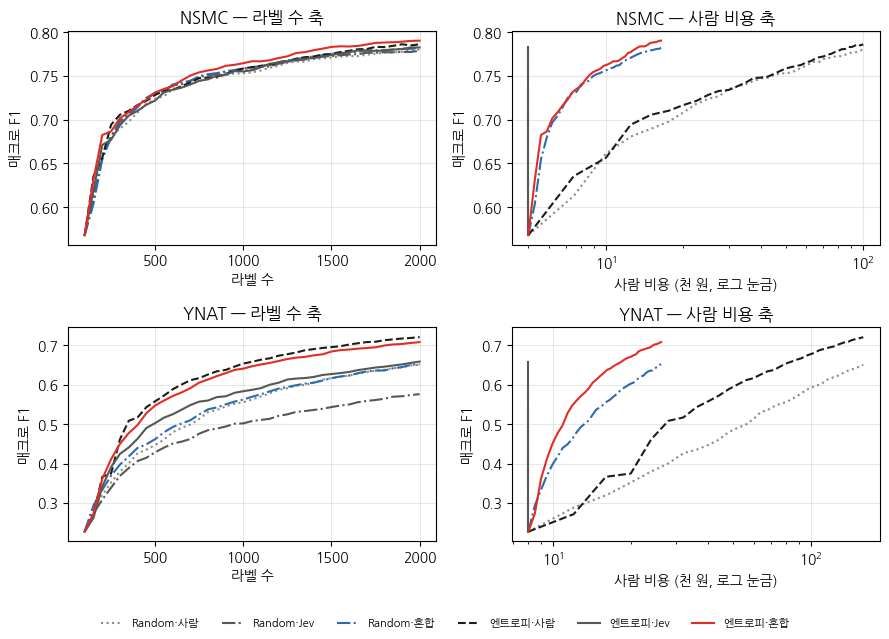

In [14]:
# ── 사람 비용 열 ────
u = res.data.map(UNIT)
res["cost_h"] = np.where(res.oracle == "사람", res.n_labeled, N_INIT) * u + REVIEW * res.reviews * u

KEYS = [f"{q}·{o}" for q in ("Random", "엔트로피") for o in ORACLES]
STY16 = dict(zip(KEYS, [(GRAY2, ":"), (GRAY, "-."), ("#2B6CB0", "-."), (INK, "--"), (GRAY, "-"), (ACCENT, "-")]))

fig, axes = plt.subplots(2, 2, figsize=(9, 6.4))
for i, name in enumerate(DATA):
    for key in KEYS:
        g = res[(res.data == name) & (res.key == key)].groupby("n_labeled")[["f1", "cost_h"]].mean()
        c, ls = STY16[key]
        axes[i, 0].plot(g.index, g.f1, color=c, ls=ls, lw=1.5, label=key)
        axes[i, 1].plot(g.cost_h / 1000, g.f1, color=c, ls=ls, lw=1.5, label=key)
    axes[i, 0].set(title=f"{name.upper()} — 라벨 수 축", xlabel="라벨 수", ylabel="매크로 F1")
    axes[i, 1].set(title=f"{name.upper()} — 사람 비용 축", xlabel="사람 비용 (천 원, 로그 눈금)", ylabel="매크로 F1", xscale="log")
    for ax in axes[i]:
        ax.grid(alpha=0.3)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=6, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("out/ch16_curves.png", dpi=200)

for name in DATA:
    r = res[res.data == name].assign(strategy=lambda x: x.key, t_query=np.nan)
    t = summarize(r, "f1", ref="Random·사람").set_index("strategy").loc[KEYS, ["ALC", "ALC_std", "final", "LE"]]
    print(f"\n{name} 매크로 F1 (LE 기준: Random·사람의 라벨 2,000 성능)")
    print(t.to_string())

## 16.4 비용 모델 — 사람 라벨 단가와 API 호출 비용

비용은 사람 몫과 Jev 몫으로 나눈다. 사람 몫은 위의 사람 비용 C_H, Jev 몫은 입력 토큰 T_in × 토큰 단가 p다. 이 책은 토큰 단가를 정하지 않는다. 대신 「목표 F1에 이르는 데 사람 오라클과 같은 돈이 드는 토큰 단가」를 손익분기 단가 p*로 낸다.

p* = (사람 오라클의 C_H − Jev·혼합 오라클의 C_H) / Jev·혼합 오라클의 T_in

실제 토큰 단가가 p*보다 낮으면 Jev 쪽이 싸다. p*가 클수록 Jev가 유리하다. 목표 F1에 이르는 라벨 수는 시드 평균 곡선이 그 F1을 처음 넘는 지점이다. 비교 상대는 같은 질의 전략의 사람 오라클이다. 목표 F1에 이르지 못한 오라클은 p*를 내지 않는다.

먼저 라벨 2,000개 시점의 비교표(표 16.1)를 만든다. 시간 열은 16.5절에서 채운다.

In [15]:
# ── 라벨 2,000개 시점 비교 (표 16.1 앞부분) ────
last = res[res.n_labeled == BUDGET].groupby(["data", "key"]).agg(noise=("noise", "mean"), final=("f1", "mean"),
                                                                 cost_h=("cost_h", "mean"), tok=("tok", "mean"),
                                                                 reviews=("reviews", "mean"))
alcs = res.groupby(["data", "key", "seed"]).apply(lambda x: alc(x.n_labeled.values, x.f1.values), include_groups=False)
tab1 = last.join(alcs.groupby(["data", "key"]).mean().rename("ALC"))
tab1["label_acc"] = 1 - tab1.noise * BUDGET / (BUDGET - N_INIT)
for name in DATA:
    print(f"\n{name} (label_acc = 질의 라벨 1,900개 정확도, cost_h = 사람 비용(원), tok = Jev 입력 토큰)")
    print(tab1.loc[name].loc[KEYS, ["label_acc", "ALC", "final", "cost_h", "reviews", "tok"]].round(4).to_string())


nsmc (label_acc = 질의 라벨 1,900개 정확도, cost_h = 사람 비용(원), tok = Jev 입력 토큰)
            label_acc     ALC   final    cost_h  reviews          tok
key                                                                  
Random·사람      1.0000  0.7426  0.7802  100000.0      0.0       0.0000
Random·Jev     0.8997  0.7452  0.7788    5000.0      0.0  155285.2000
Random·혼합      0.9642  0.7463  0.7821   16400.0    380.0  155285.2000
엔트로피·사람        1.0000  0.7479  0.7860  100000.0      0.0       0.0000
엔트로피·Jev       0.8562  0.7450  0.7825    5000.0      0.0  155163.2000
엔트로피·혼합        0.9381  0.7528  0.7902   16400.0    380.0  176475.8647

ynat (label_acc = 질의 라벨 1,900개 정확도, cost_h = 사람 비용(원), tok = Jev 입력 토큰)
            label_acc     ALC   final    cost_h  reviews          tok
key                                                                  
Random·사람      1.0000  0.5335  0.6500  160000.0      0.0       0.0000
Random·Jev     0.8299  0.4840  0.5758    8000.0      0.0  212907.2000
Random·혼합     


nsmc 손익분기 단가 p* (원 / 100만 입력 토큰, NaN = 목표 미달)
key     Random·Jev  Random·혼합  엔트로피·Jev   엔트로피·혼합
target                                           
0.70      725584.0   653026.0  480344.0  496622.0
0.71      708887.0   635973.0  502464.0  397112.0
0.72      690904.0   618359.0  531514.0  488470.0
0.73      756700.0   684057.0  607606.0  555564.0
0.74      664796.0   657802.0  609429.0  533626.0
0.75      698414.0   625081.0  649572.0  664137.0
0.76      673163.0   599727.0  552229.0  579723.0
0.77      657890.0   610384.0  588319.0  550059.0
0.78           NaN   591310.0  526455.0  555068.0
0.79           NaN        NaN       NaN       NaN
nsmc 목표에 이른 라벨 수 (사람 오라클 기준은 같은 질의 전략)
key     Random·사람  엔트로피·사람  Random·Jev  Random·혼합  엔트로피·Jev  엔트로피·혼합
target                                                              
0.70        400.0    300.0       350.0      350.0     350.0    300.0
0.71        450.0    350.0       400.0      400.0     400.0    400.0
0.72        500.0    450.0       450.0

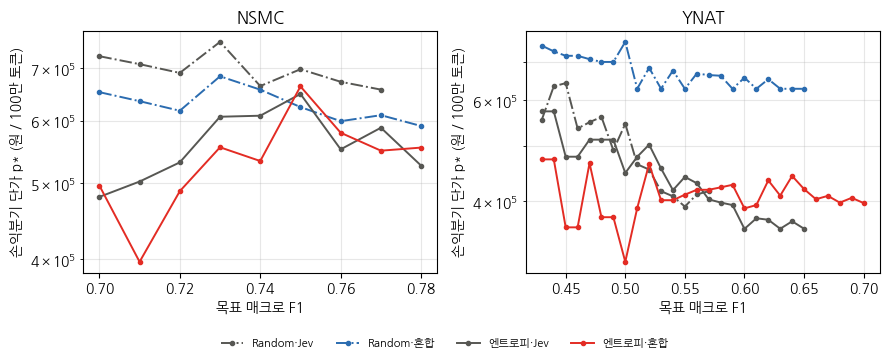

In [16]:
# ── 손익분기 단가 ────
def reach(g, target):
    # 시드 평균 곡선이 target을 처음 넘는 라벨 수와 그때의 사람 비용·토큰
    m = g.groupby("n_labeled")[["f1", "cost_h", "tok"]].mean()
    hit = m[m.f1 >= target]
    return hit.iloc[0] if len(hit) else None

PER = 1e6                                                       # p*는 입력 토큰 100만 개당 원으로 적는다
be = []
for name in DATA:
    r = res[res.data == name]
    top = r[r.n_labeled == BUDGET].groupby("key").f1.mean()
    targets = np.round(np.arange(np.ceil(r[(r.oracle == "사람") & (r.n_labeled == 300)].f1.mean() * 100) / 100,
                                 top.drop(["Random·사람", "엔트로피·사람"]).max() + 1e-9, 0.01), 2)
    for q in ("Random", "엔트로피"):
        for o in ("Jev", "혼합"):
            for tg in targets:
                h, x = reach(r[r.key == f"{q}·사람"], tg), reach(r[r.key == f"{q}·{o}"], tg)
                be.append(dict(data=name, key=f"{q}·{o}", target=tg, n_h=None if h is None else h.name,
                               n_x=None if x is None else x.name,
                               p_star=np.nan if h is None or x is None else (h.cost_h - x.cost_h) / x.tok * PER))
be = pd.DataFrame(be)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, DATA):
    for key in [k for k in KEYS if not k.endswith("사람")]:
        g = be[(be.data == name) & (be.key == key)]
        c, ls = STY16[key]
        ax.plot(g.target, g.p_star, color=c, ls=ls, marker="o", ms=3, lw=1.4, label=key)
    ax.set(title=name.upper(), xlabel="목표 매크로 F1", ylabel="손익분기 단가 p* (원 / 100만 토큰)", yscale="log")
    ax.grid(alpha=0.3, which="both")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig("out/ch16_breakeven.png", dpi=200)

for name in DATA:
    t = be[be.data == name].pivot(index="target", columns="key", values="p_star")
    n = be[be.data == name].pivot(index="target", columns="key", values="n_x")
    print(f"\n{name} 손익분기 단가 p* (원 / 100만 입력 토큰, NaN = 목표 미달)")
    print(t.round(0).to_string())
    print(f"{name} 목표에 이른 라벨 수 (사람 오라클 기준은 같은 질의 전략)")
    print(be[be.data == name].pivot(index="target", columns="key", values="n_h").iloc[:, [0, 2]].rename(
        columns=lambda c: c.replace("Jev", "사람")).join(n).to_string())

## 16.5 소요 시간 비교

사람 오라클의 시간은 00_기획안 4.2절의 건당 시간(NSMC 8초, YNAT 12초) × 라벨 수로 잡는다. 라벨러 한 사람이 차례로 붙인다고 본 시간이다. Jev 오라클의 시간은 노트북에서 잰 실제 호출 시간이다. Random 칸은 이 장에서 잰 값(라벨 저장소의 문장별 몫)이고, 엔트로피 칸은 15장 저장소에 시간이 없어 13장 루프에서 잰 라운드당 호출 시간을 쓴다. 혼합 오라클은 Jev 호출 시간에 검수 시간(건당 시간의 60%)을 더한다.

라운드당 대기 시간은 질의 50개를 보내고 라벨을 받을 때까지 루프가 멈추는 시간이다.

In [17]:
# ── 소요 시간 ────
R = (BUDGET - N_INIT) // K                                          # 라운드 수 38
t13 = ch13.groupby(["data", "strategy"]).t_jev.mean()                # 13장에서 잰 라운드당 Jev 호출 시간(초)
rows = []
for name in DATA:
    for key in KEYS:
        q, o = key.split("·")
        x = tab1.loc[(name, key)]
        if o == "사람":
            jev_round = 0.0
        elif q == "Random":
            jev_round = res[(res.data == name) & (res.key == key) & (res.n_labeled == BUDGET)].t_jev.mean() / R
        else:
            jev_round = t13.loc[(name, f"{q}·Jev")]
        human_sec = (BUDGET - N_INIT) * SEC[name] if o == "사람" else REVIEW * x.reviews * SEC[name]
        rows.append(dict(data=name, key=key, jev_s_per_round=jev_round, human_s_per_round=human_sec / R,
                         wait_s_per_round=jev_round + human_sec / R, total_h=(jev_round * R + human_sec) / 3600))
tt = pd.DataFrame(rows).set_index(["data", "key"])
print("13장에서 잰 라운드당 Jev 호출 시간(초):", t13.round(3).to_dict())
for name in DATA:
    print(f"\n{name} 소요 시간 (질의 1,900개, total_h = 라벨 붙이는 데 든 시간 합)")
    print(tt.loc[name].round(3).to_string())

tab1 = tab1.join(tt.total_h)
print("\n표 16.1 오라클 비교 (라벨 2,000개 시점)")
print(tab1[["label_acc", "ALC", "final", "cost_h", "tok", "total_h"]].round(4).to_string())

13장에서 잰 라운드당 Jev 호출 시간(초): {('nsmc', 'Random·Jev'): 0.206, ('nsmc', '엔트로피·Jev'): 0.207, ('ynat', 'Random·Jev'): 0.254, ('ynat', '엔트로피·Jev'): 0.253}

nsmc 소요 시간 (질의 1,900개, total_h = 라벨 붙이는 데 든 시간 합)
            jev_s_per_round  human_s_per_round  wait_s_per_round  total_h
key                                                                      
Random·사람             0.000              400.0           400.000    4.222
Random·Jev            0.206                0.0             0.206    0.002
Random·혼합             0.206               48.0            48.206    0.509
엔트로피·사람               0.000              400.0           400.000    4.222
엔트로피·Jev              0.207                0.0             0.207    0.002
엔트로피·혼합               0.207               48.0            48.207    0.509

ynat 소요 시간 (질의 1,900개, total_h = 라벨 붙이는 데 든 시간 합)
            jev_s_per_round  human_s_per_round  wait_s_per_round  total_h
key                                                                      
Random·사람 

## 16.6 혼합 오라클 구성

목표에 따라 어떤 오라클 설정이 가장 싼지 고른다. 후보는 15장에서 엔트로피 질의로 돌린 모든 설정(검수 기준 4개 × 비율 4개, 임계값, 검수 없음, 노이즈 강건 학습 6개)과 엔트로피·사람 오라클이다. 목표마다 그 목표를 넘는 후보 가운데 사람 비용이 가장 적은 것을 고르고, 비용이 같으면 ALC가 높은 것을 고른다. 사람 비용이 같은 후보 사이에서 Jev 토큰은 거의 같으므로(질의 수가 같다) 사람 비용만 본다.

In [18]:
# ── 목표별 권장 설정 (표 16.2) ────
import glob
c15 = pd.concat([pd.read_csv(f) for f in glob.glob("results/ch15_parts/loop_*.csv")], ignore_index=True)
c15 = pd.concat([c15, res[res.key == "엔트로피·사람"].assign(arm="사람 오라클")], ignore_index=True)
c15["cost_h"] = np.where(c15.arm == "사람 오라클", c15.n_labeled * c15.data.map(UNIT),
                         (N_INIT + REVIEW * c15.reviews) * c15.data.map(UNIT))
cand = c15.groupby(["data", "arm"]).apply(lambda g: pd.Series(dict(
    ALC=np.mean([alc(x.n_labeled.values, x.f1.values) for _, x in g.groupby("seed")]),
    final=g[g.n_labeled == BUDGET].f1.mean(),
    label_acc=1 - g[g.n_labeled == BUDGET].noise.mean() * BUDGET / (BUDGET - N_INIT),
    cost_h=g[g.n_labeled == BUDGET].cost_h.mean(), tok=g[g.n_labeled == BUDGET].tok.mean())), include_groups=False)

rec = []
for name in DATA:
    c, hum = cand.loc[name], cand.loc[(name, "사람 오라클")]
    goals = {"라벨 정확도 ≥ 0.90": c.label_acc >= 0.90, "라벨 정확도 ≥ 0.95": c.label_acc >= 0.95,
             "ALC ≥ 사람 오라클의 98%": c.ALC >= 0.98 * hum.ALC, "ALC ≥ 사람 오라클의 99%": c.ALC >= 0.99 * hum.ALC,
             "ALC ≥ 사람 오라클": c.ALC >= hum.ALC, "최종 F1 ≥ 사람 오라클 − 0.01": c.final >= hum.final - 0.01}
    for goal, ok in goals.items():
        best = c[ok].sort_values(["cost_h", "ALC"], ascending=[True, False]).iloc[0]
        rec.append(dict(data=name, goal=goal, arm=best.name, cost_h=best.cost_h, cost_ratio=best.cost_h / hum.cost_h,
                        label_acc=best.label_acc, ALC=best.ALC, final=best.final, tok=best.tok))
rec = pd.DataFrame(rec)
for name in DATA:
    print(f"\n{name} 목표별 가장 싼 설정 (cost_ratio = 사람 오라클 대비 사람 비용, 사람 오라클: ALC {cand.loc[(name, '사람 오라클'), 'ALC']:.4f}, "
          f"최종 F1 {cand.loc[(name, '사람 오라클'), 'final']:.4f})")
    print(rec[rec.data == name].drop(columns="data").set_index("goal").round(4).to_string())


nsmc 목표별 가장 싼 설정 (cost_ratio = 사람 오라클 대비 사람 비용, 사람 오라클: ALC 0.7479, 최종 F1 0.7860)
                               arm   cost_h  cost_ratio  label_acc     ALC   final          tok
goal                                                                                           
라벨 정확도 ≥ 0.90               결합 10%  10700.0       0.107     0.9049  0.7485  0.7883  192442.8955
라벨 정확도 ≥ 0.95              신뢰도 30%  22100.0       0.221     0.9594  0.7517  0.7931  177940.2783
ALC ≥ 사람 오라클의 98%      r0 · 라벨 평활화   5000.0       0.050     0.8536  0.7541  0.7912  203675.7063
ALC ≥ 사람 오라클의 99%      r0 · 라벨 평활화   5000.0       0.050     0.8536  0.7541  0.7912  203675.7063
ALC ≥ 사람 오라클           r0 · 라벨 평활화   5000.0       0.050     0.8536  0.7541  0.7912  203675.7063
최종 F1 ≥ 사람 오라클 − 0.01  r0 · 라벨 평활화   5000.0       0.050     0.8536  0.7541  0.7912  203675.7063

ynat 목표별 가장 싼 설정 (cost_ratio = 사람 오라클 대비 사람 비용, 사람 오라클: ALC 0.6164, 최종 F1 0.7202)
                                    arm    cost_h  cost_ratio  lab

In [19]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
files = glob.glob("results/ch16_parts/jev_*.csv")
total = sum(pd.read_csv(f).n_in.sum() for f in files)
print(f"Jev 라벨 저장소에 기록된 입력 토큰 합: {total:,.0f} (라벨 {sum(len(pd.read_csv(f)) for f in files):,}개)")

Jev 라벨 저장소에 기록된 입력 토큰 합: 1,840,962 (라벨 19,000개)
